# Prototipo funcional · Anticipación de cupos por programa y año de estudio
Desarrollo de Soluciones Inteligentes (UBO) · Proyecto Integrador · EVAL-01 (13-11-2026)

**Equipo / integrantes y paralelo de cada uno:** ← *completar (todos los nombres y paralelos)*

**Problema.** Planificación académica necesita saber cuántos estudiantes de cada cohorte seguirán el próximo año en el mismo programa, para dimensionar secciones, docentes y salas de los años superiores.
**Qué hace el prototipo.** Recibe cohortes (caso a caso, o una tabla), valida los datos, aplica un modelo Ridge ya entrenado (sin reajustarlo) y entrega la continuidad estimada, los estudiantes esperados y los cupos esperados por programa y año de estudio, con avisos cuando la estimación es menos fiable.
**Alcance.** Cupos por programa y año de estudio, no por asignatura (la base SIES no trae asignaturas).

Para ejecutarlo: dejar `modelo_continuidad.joblib`, `contrato_modelo.json`, `cupos_app.py`, `casos_prueba.py`, `datos_ejemplo/` y `evidencia/` junto a este notebook (en Colab, subir el zip del prototipo y descomprimir en la primera celda). Dependencias en `requirements.txt`.

In [1]:
import os, sys, glob, zipfile, json, platform
z = glob.glob('/content/*.zip') + glob.glob('*.zip')
if not z and not glob.glob('**/cupos_app.py', recursive=True):
    from google.colab import files
    files.upload(); z = glob.glob('*.zip')
if z:
    zipfile.ZipFile(z[0]).extractall('.')   # siempre se vuelve a extraer: evita quedarse con una versión antigua
os.chdir(os.path.dirname(os.path.abspath(glob.glob('**/cupos_app.py', recursive=True)[0])))
sys.path.insert(0, os.getcwd())
sys.modules.pop('cupos_app', None); sys.modules.pop('casos_prueba', None)
import numpy as np, pandas as pd, sklearn, matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import cupos_app as app
assert hasattr(app, '_parsear'), 'cupos_app.py es una versión antigua: borre la carpeta PI06_Prototipo_Cupos, reinicie la sesión y vuelva a ejecutar'
from casos_prueba import ejecutar_casos
pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 120)
M = app.Modelo()   # verifica la huella del modelo contra el contrato antes de cargarlo
print('python', platform.python_version(), '| pandas', pd.__version__, '| scikit-learn', sklearn.__version__)
print('modelo creado con scikit-learn', M.contrato['versiones']['sklearn'], '| entrenado con', M.contrato['filas_entrenamiento'], 'cohortes (t = 2019-2024)')

python 3.13.16 | pandas 2.2.3 | scikit-learn 1.8.0
modelo creado con scikit-learn 1.8.0 | entrenado con 4731 cohortes (t = 2019-2024)


## Demo en vivo: ingresar datos y predecir
Escriba o cambie los datos de una cohorte y pulse **Predecir**. Las listas desplegables traen las categorías válidas. Los campos opcionales pueden quedar vacíos. Para ver el rechazo, cargue un caso de prueba o escriba un valor inválido (por ejemplo arancel 55 o n_t 4).

In [2]:
import ipywidgets as w
from IPython.display import display, HTML, clear_output
base = json.load(open('datos_ejemplo/caso_valido.json', encoding='utf-8'))
PRESETS = {'Cohorte válida (real, 2024)': {}, 'Arancel en UF': dict(arancel_anual_clp=55.0), 'Cohorte de 4 estudiantes': dict(n_t=4),
           'Proporción mayor que 1': dict(ret_prev=1.4), 'CFT (aviso de error alto)': dict(tipo_inst_1='Centros de Formación Técnica'),
           'Sin historial ni edad (aviso)': dict(n_prev=None, ret_prev=None, edad_media=None), 'Último año de la carrera': dict(anio_ingreso=2022)}
est = {'description_width': '190px'}; lay = w.Layout(width='470px')
CAMPOS_W = {}
for n, tipo, lo, hi, obl, un in app.NUMERICOS:
    CAMPOS_W[n] = w.Text(description=f"{n} ({un}){'' if obl else ' *'}", style=est, layout=lay)
for c in app.CATEGORICOS:
    CAMPOS_W[c] = w.Dropdown(options=M.categorias[c], description=c, style=est, layout=lay)
def cargar(valores):
    for k, wd in CAMPOS_W.items():
        v = valores.get(k)
        wd.value = ('' if v is None else str(v)) if isinstance(wd, w.Text) else v
cargar(base)
sel = w.Dropdown(options=list(PRESETS), description='Cargar caso:', style=est, layout=lay)
sel.observe(lambda ch: cargar({**base, **PRESETS[ch['new']]}), names='value')
btn = w.Button(description='Predecir', button_style='primary'); salida = w.Output()
def predecir_ui(_):
    with salida:
        clear_output()
        entrada = {k: (app._parsear(wd.value) if isinstance(wd, w.Text) else wd.value) for k, wd in CAMPOS_W.items()}
        r = app.predecir(M, entrada); app._mostrar(r)
        if r['estado'] == 'OK':
            display(HTML(f"<h3>De {entrada['n_t']} estudiantes, se estima que {r['prediccion']*100:.0f}% (unos {r['estudiantes_esperados']:.1f}) seguirá en el mismo programa el año siguiente.</h3>"
                         f"<p>Error típico de referencia: ±{r['error_tipico_pp']} puntos porcentuales. Es una estimación, no una certeza.</p>"))
btn.on_click(predecir_ui)
display(w.VBox([sel] + list(CAMPOS_W.values()) + [w.HTML('<small>* opcional: puede quedar vacío</small>'), btn, salida]))

## 1. Arquitectura

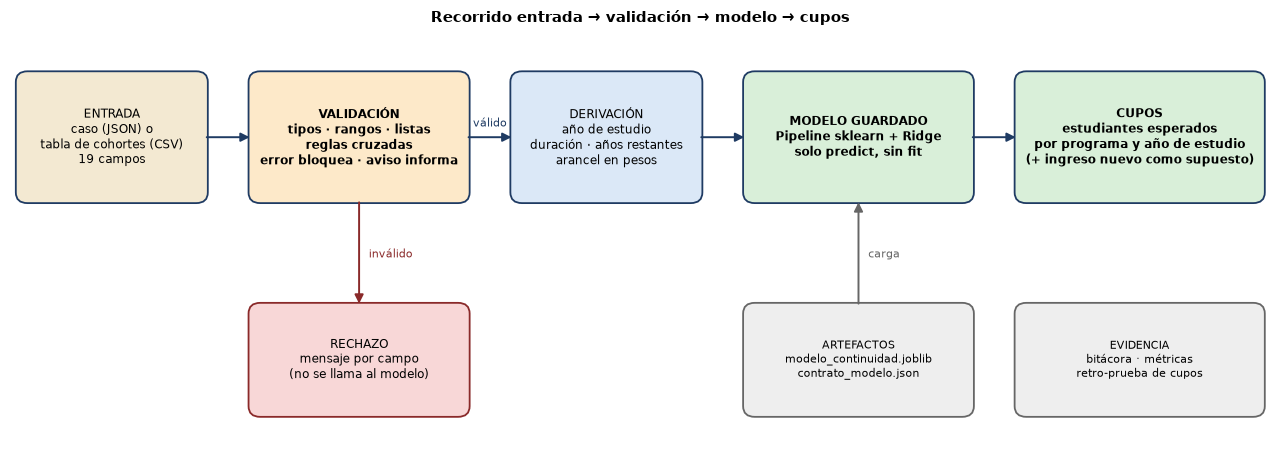

In [3]:
fig, ax = plt.subplots(figsize=(13, 4.6)); ax.set_xlim(0, 13); ax.set_ylim(0, 4.6); ax.axis('off')
def caja(x, y, w, h, t, c='#dbe8f7', ec='#1f3b63', fs=8.8, b=False):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.04,rounding_size=0.12', fc=c, ec=ec, lw=1.3))
    ax.text(x + w / 2, y + h / 2, t, ha='center', va='center', fontsize=fs, fontweight='bold' if b else 'normal')
def fl(x1, y1, x2, y2, t='', c='#1f3b63'):
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle='-|>', mutation_scale=13, lw=1.4, color=c))
    if t: ax.text((x1 + x2) / 2, (y1 + y2) / 2 + .12, t, ha='center', fontsize=7.8, color=c)
caja(.1, 2.7, 1.9, 1.4, 'ENTRADA\ncaso (JSON) o\ntabla de cohortes (CSV)\n19 campos', c='#f3e9d2')
caja(2.5, 2.7, 2.2, 1.4, 'VALIDACIÓN\ntipos · rangos · listas\nreglas cruzadas\nerror bloquea · aviso informa', c='#fde9c9', b=True)
caja(5.2, 2.7, 1.9, 1.4, 'DERIVACIÓN\naño de estudio\nduración · años restantes\narancel en pesos')
caja(7.6, 2.7, 2.3, 1.4, 'MODELO GUARDADO\nPipeline sklearn + Ridge\nsolo predict, sin fit', c='#d9efd9', b=True)
caja(10.4, 2.7, 2.5, 1.4, 'CUPOS\nestudiantes esperados\npor programa y año de estudio\n(+ ingreso nuevo como supuesto)', c='#d9efd9', b=True)
caja(2.5, .3, 2.2, 1.2, 'RECHAZO\nmensaje por campo\n(no se llama al modelo)', c='#f8d7d7', ec='#8a2a2a')
caja(7.6, .3, 2.3, 1.2, 'ARTEFACTOS\nmodelo_continuidad.joblib\ncontrato_modelo.json', c='#eeeeee', ec='#666666', fs=8.2)
caja(10.4, .3, 2.5, 1.2, 'EVIDENCIA\nbitácora · métricas\nretro-prueba de cupos', c='#eeeeee', ec='#666666', fs=8.2)
fl(2.0, 3.4, 2.5, 3.4); fl(4.7, 3.4, 5.2, 3.4, 'válido'); fl(7.1, 3.4, 7.6, 3.4); fl(9.9, 3.4, 10.4, 3.4)
fl(3.6, 2.7, 3.6, 1.5, c='#8a2a2a'); ax.text(3.7, 2.05, 'inválido', fontsize=7.8, color='#8a2a2a')
fl(8.75, 1.5, 8.75, 2.7, c='#666666'); ax.text(8.85, 2.05, 'carga', fontsize=7.8, color='#666666')
ax.set_title('Recorrido entrada → validación → modelo → cupos', fontweight='bold', fontsize=11)
fig.tight_layout(); os.makedirs('evidencia', exist_ok=True); fig.savefig('evidencia/arquitectura.png', dpi=160); plt.show()

## 2. Contrato de entrada

In [4]:
tabla = pd.DataFrame([dict(campo=n, tipo=t, minimo=lo, maximo=hi, obligatorio=o, unidad=u) for n, t, lo, hi, o, u in app.NUMERICOS] +
                     [dict(campo=c, tipo='texto', minimo=None, maximo=None, obligatorio=True, unidad='lista cerrada de entrenamiento') for c in app.CATEGORICOS])
display(tabla)
print('Reglas cruzadas: anio_ingreso <= anio_t; n_t <= prog_total_t; n_prev y ret_prev van juntos; cohorte nueva sin historial; la cohorte debe tener un año nominal por delante.')

,campo,tipo,minimo,maximo,obligatorio,unidad
0,anio_t,entero,2019.0,2.040000e+03,True,año
1,anio_ingreso,entero,1990.0,NaN,True,año
2,n_t,entero,5.0,1.000000e+06,True,estudiantes
3,prog_total_t,entero,1.0,1.000000e+06,True,estudiantes
4,n_prev,entero,1.0,1.000000e+06,False,estudiantes
5,ret_prev,real,0.0,1.000000e+00,False,proporción
6,prop_mujer,real,0.0,1.000000e+00,True,proporción
7,edad_media,real,14.0,9.000000e+01,False,años
8,dur_semestres,entero,1.0,2.000000e+01,True,semestres
9,arancel_anual_clp,real,10000.0,1.000000e+10,False,pesos chilenos por año


Reglas cruzadas: anio_ingreso <= anio_t; n_t <= prog_total_t; n_prev y ret_prev van juntos; cohorte nueva sin historial; la cohorte debe tener un año nominal por delante.


## 3. Demostración con un caso: entrada → proceso → resultado

In [5]:
caso = json.load(open('datos_ejemplo/caso_valido.json', encoding='utf-8'))   # cohorte real 2024 observada en 2025
print(json.dumps({k: caso[k] for k in list(caso)[:10]}, ensure_ascii=False)); print('... + 9 campos de texto')
r = app.predecir(M, caso); app._mostrar(r)

{"anio_t": 2025, "anio_ingreso": 2024, "n_t": 10, "n_prev": 18, "ret_prev": 0.3889, "prog_total_t": 26, "prop_mujer": 0.3, "edad_media": 32.8, "dur_semestres": 8, "arancel_anual_clp": 2000000.0}
... + 9 campos de texto
ESTADO: OK
  continuidad estimada: 0.519 | estudiantes esperados: 5.2 | año de estudio siguiente: 3 | error típico: ±13.3 pp


In [6]:
# Entradas inválidas: se rechazan antes del modelo
antes = M.llamadas
for nombre, cambio in [('arancel en UF', dict(arancel_anual_clp=55.0)), ('región inexistente', dict(region_sede='Narnia')),
                       ('proporción mayor que 1', dict(ret_prev=1.4)), ('cohorte de 4 estudiantes', dict(n_t=4))]:
    print('>>', nombre); app._mostrar(app.predecir(M, {**caso, **cambio}))
print('\nllamadas al modelo en los 4 casos inválidos:', M.llamadas - antes)

>> arancel en UF
ESTADO: RECHAZADA
  ERROR       : arancel_anual_clp=55: parece estar en UF; debe informarse en pesos chilenos por año (mínimo 10,000)
>> región inexistente
ESTADO: RECHAZADA
  ERROR       : region_sede: categoría no reconocida ('Narnia'); opciones: Antofagasta, Arica y Parinacota, Atacama, Aysén, Biobío, Coquimbo, La Araucanía, Lib. Gral. B. O'Higgins, Los Lagos, Los Ríos, Magallanes, Maule, Metropolitana, Tarapacá, Valparaíso, Ñuble
>> proporción mayor que 1
ESTADO: RECHAZADA
  ERROR       : ret_prev=1.4: mayor que el máximo permitido (1.0 proporción)
>> cohorte de 4 estudiantes
ESTADO: RECHAZADA
  ERROR       : n_t=4: una cohorte de menos de 5 estudiantes no es estimable (el modelo se entrenó con 5 o más)

llamadas al modelo en los 4 casos inválidos: 0


## 4. Modo lote: de cohortes a cupos por programa y año de estudio

In [7]:
cohortes = app._csv_a_df('datos_ejemplo/cohortes_2025.csv')       # 770 cohortes observadas en 2025 (datos agregados, sin personas)
detalle, cupos = app.proyectar_lote(M, cohortes)
print(detalle.estado.value_counts().to_dict(), '| cohortes con algún aviso:', int((detalle.mensajes != '').sum()))
p = cupos.programa.iloc[40]
print('\nEjemplo, programa', p, '(cupos esperados en 2026):'); display(cupos[cupos.programa == p])
display(cupos.groupby('anio_estudio_t1').cupos_esperados.agg(['count', 'sum']).round(0).rename(columns={'count': 'programas', 'sum': 'cupos_esperados'}))

{'OK': 770} | cohortes con algún aviso: 123

Ejemplo, programa I100S23C21J1V1 (cupos esperados en 2026):


,programa,anio_estudio_t1,cupos_esperados,origen
38,I100S23C21J1V1,1,63.0,supuesto: igual al ingreso de t
39,I100S23C21J1V1,2,47.1,continuidad (modelo)
40,I100S23C21J1V1,3,41.7,continuidad (modelo)
41,I100S23C21J1V1,4,21.7,continuidad (modelo)


,programas,cupos_esperados
anio_estudio_t1,,
1,350,17883.0
2,305,13016.0
3,246,9276.0
4,148,5325.0
5,60,2251.0
6,11,439.0


El año 1 de 2026 no lo predice el modelo: se toma el ingreso observado en 2025 como **supuesto** (o un ingreso proyectado entregado por el usuario). Está marcado en la columna `origen`.
## 5. Pruebas: bitácora de 20 casos (ejecución en vivo)

In [8]:
BIT, _ = ejecutar_casos(app.Modelo())
display(BIT[['caso', 'tipo', 'proposito', 'estado_observado', 'llamadas_modelo', 'resultado']])
print(f"{(BIT.resultado == 'Cumple').sum()} de {len(BIT)} casos cumplen | llamadas al modelo en casos de error:", int(BIT[BIT.estado_observado == 'RECHAZADA'].llamadas_modelo.sum()))

,caso,tipo,proposito,estado_observado,llamadas_modelo,resultado
0,CP-01,Normal,flujo completo con una cohorte real,OK,1,Cumple
1,CP-02,Inválido,arancel negativo,RECHAZADA,0,Cumple
2,CP-03,Incompleto,falta un campo obligatorio (prop_mujer),RECHAZADA,0,Cumple
3,CP-04,Inválido,texto en campo numérico,RECHAZADA,0,Cumple
4,CP-05,Integración,misma predicción que el pipeline de referencia,OK,1,Cumple
5,CP-06,Fuera de rango,arancel tres veces el máximo de entrenamiento,OK,1,Cumple
6,CP-07,Límite,n_t = 0,RECHAZADA,0,Cumple
7,CP-08,Límite,"n_t = 4, justo bajo el mínimo del contrato",RECHAZADA,0,Cumple
8,CP-09,No finito,NaN en ret_prev,RECHAZADA,0,Cumple
9,CP-10,No finito,infinito en el arancel,RECHAZADA,0,Cumple


20 de 20 casos cumplen | llamadas al modelo en casos de error: 0


### Pruebas ampliadas (resultados guardados en `evidencia/`)
Además de la bitácora hay dos suites que se ejecutan aparte (`pruebas_escenarios.py` y `pruebas_adversarias.py`, cerca de un minuto cada una). Aquí se leen sus resultados.

In [9]:
ESC = json.load(open('evidencia/resumen_escenarios.json', encoding='utf-8'))
ADV = pd.read_csv('evidencia/pruebas_adversarias.csv')
print(f"Escenarios contra el verificador independiente: {ESC['cumplen']:,} de {ESC['total']:,} cumplen | excepciones: {ESC['excepciones']} | rechazos que llegaron al modelo: {ESC['rechazados_que_llegaron_al_modelo']}")
print(f"Casos adversarios: {(ADV.resultado == 'Cumple').sum()} de {len(ADV)} cumplen")
display(ADV.groupby('grupo').resultado.value_counts().unstack(fill_value=0))

Escenarios contra el verificador independiente: 41,282 de 41,282 cumplen | excepciones: 0 | rechazos que llegaron al modelo: 0
Casos adversarios: 120 de 120 cumplen


resultado,Cumple
grupo,
CSV,14
concurrencia,3
consistencia,5
integridad,5
lote,15
línea de comandos,8
números escritos a mano,14
números extremos,15
servidor web,15


## 6. Validación con datos reales (resultados de `ejecutar_validacion.py`)
Se calcularon al ejecutar el script sobre la muestra SIES (partición temporal: entrenamiento con cohortes observadas en 2019–2024, prueba en 2025 con el objetivo construido con la matrícula 2026). Aquí solo se leen los archivos de `evidencia/`.

In [10]:
R = json.load(open('evidencia/resumen_evidencia.json', encoding='utf-8'))
print('Cohortes de entrenamiento:', R['datos']['cohortes_entrenamiento'], '| prueba:', R['datos']['cohortes_prueba'], '| SHA-256 del zip de datos:', R['datos']['sha256_zip'][:16], '...')
print('Modelo guardado = reentrenado:', R['modelo_guardado_igual_reentrenado'], '| integración app vs pipeline:', R['integracion'], '| pipeline sin cambios tras predecir:', R['sin_reajuste']['igual'])
print('\nContinuidad (proporción) en la prueba 2025'); display(pd.read_csv('evidencia/metricas_continuidad.csv', index_col=0))
print('Cupos: estudiantes continuantes esperados vs observados (2025 → 2026)'); display(pd.read_csv('evidencia/cupos_backtest_todas.csv', index_col=0))

Cohortes de entrenamiento: 4731 | prueba: 774 | SHA-256 del zip de datos: 5b69ea7154e08990 ...
Modelo guardado = reentrenado: True | integración app vs pipeline: {'cohortes_en_contrato': 770, 'coinciden': 770, 'fuera_por_arancel_en_uf': 4} | pipeline sin cambios tras predecir: True

Continuidad (proporción) en la prueba 2025


,MAE,MAE_ponderado_n,RMSE,R2,sesgo
Ridge (modelo),0.1326,0.1221,0.2063,0.2312,0.0135
Base: media de entrenamiento,0.1680,0.1656,0.2353,-0.0000,-0.0016
Base: retención del año previo,0.1538,0.1434,0.2410,-0.0497,0.0318


Cupos: estudiantes continuantes esperados vs observados (2025 → 2026)


,MAE_est_por_cohorte,WAPE_cohorte,MAE_est_por_programa,WAPE_programa,sesgo_total_pct
Modelo,6.2585,0.1662,11.2254,0.1355,4.0566
Base: todos continúan,13.5749,0.3604,29.8494,0.3604,36.0409
Base: media de entrenamiento,8.4845,0.2253,16.6449,0.2010,1.2704
Base: retención del año previo,7.3467,0.1951,12.5747,0.1518,6.4960


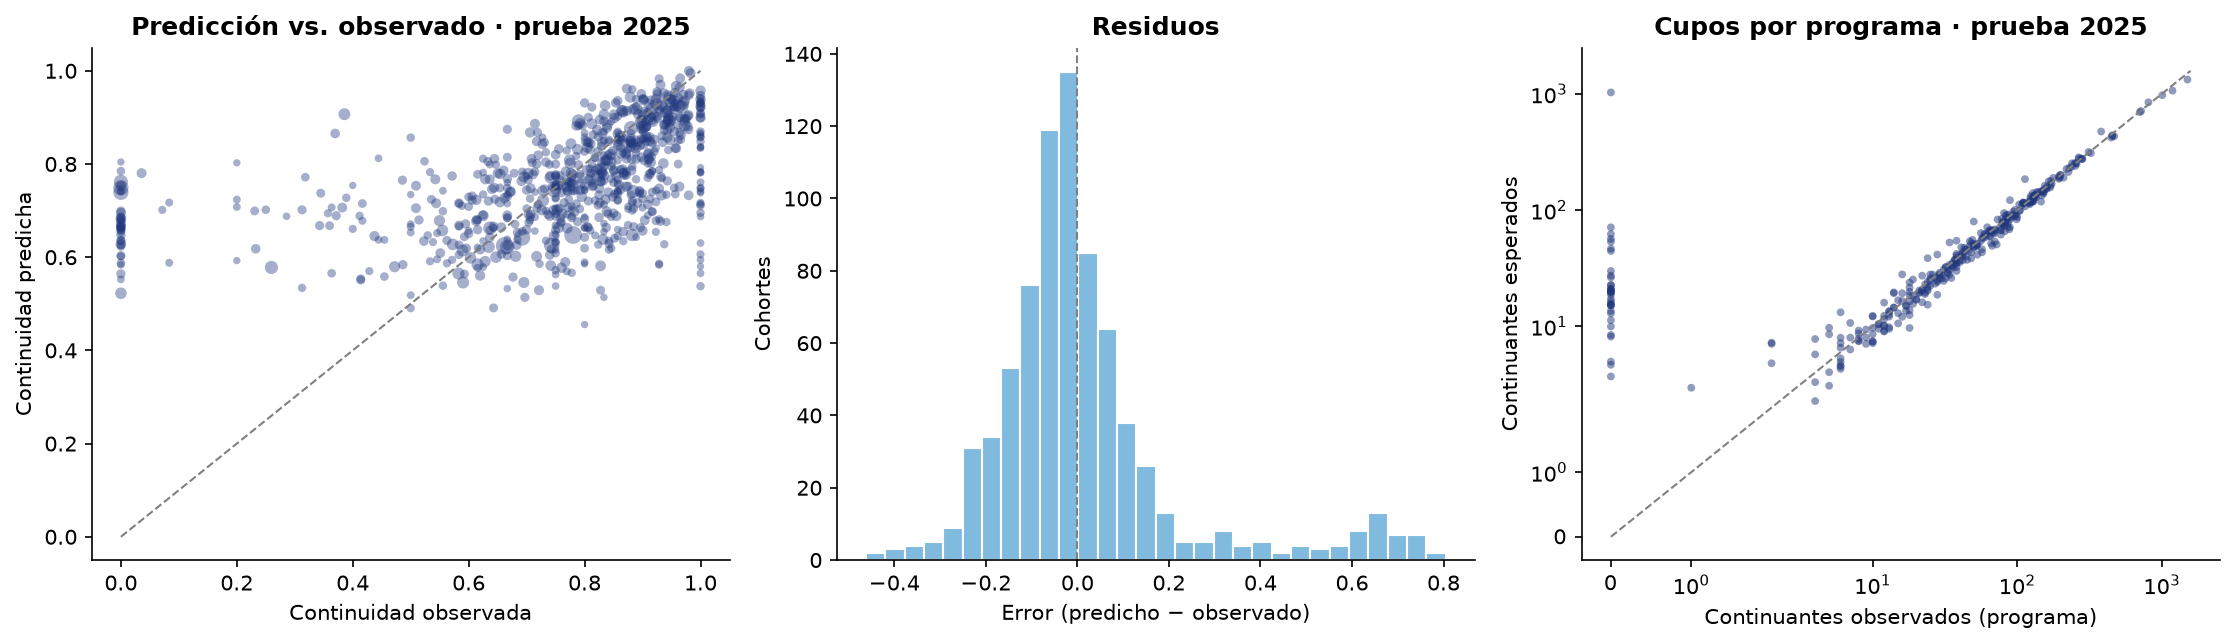

In [11]:
from IPython.display import Image, display as d2
d2(Image('evidencia/fig_desempeno.png'))

### Dónde falla

Error por tipo de institución


,cohortes,observado_medio,prediccion_media,MAE,sesgo
tipo_inst_1,,,,,
Institutos Profesionales,340,0.7050,0.7075,0.1440,0.0025
Universidades,331,0.8631,0.8444,0.0733,-0.0187
Centros de Formación Técnica,103,0.5049,0.6585,0.2853,0.1536


Solo programas cuyo código sigue existiendo en 2026


,cohortes,MAE,sesgo
tipo_inst_1,,,
Centros de Formación Técnica,76,0.1525,-0.0259
Institutos Profesionales,333,0.1333,-0.0112
Universidades,330,0.0715,-0.0208


Error por tamaño de cohorte


,cohortes,observado_medio,prediccion_media,MAE,sesgo
tramo_n_t,,,,,
20–49,334,0.7405,0.7650,0.1275,0.0245
50 o más,229,0.7685,0.7906,0.0982,0.0221
10–19,145,0.7300,0.7225,0.1643,-0.0075
5–9,66,0.7301,0.7050,0.2078,-0.0251


Cupos, solo programas con código vigente


,MAE_est_por_cohorte,WAPE_cohorte,MAE_est_por_programa,WAPE_programa,sesgo_total_pct
Modelo,4.1037,0.1040,6.7080,0.0734,-2.1571
Base: todos continúan,10.7226,0.2718,24.8401,0.2718,27.1807
Base: media de entrenamiento,6.2844,0.1593,12.3391,0.1350,-5.3252
Base: retención del año previo,5.0893,0.1290,7.8399,0.0858,-0.1083


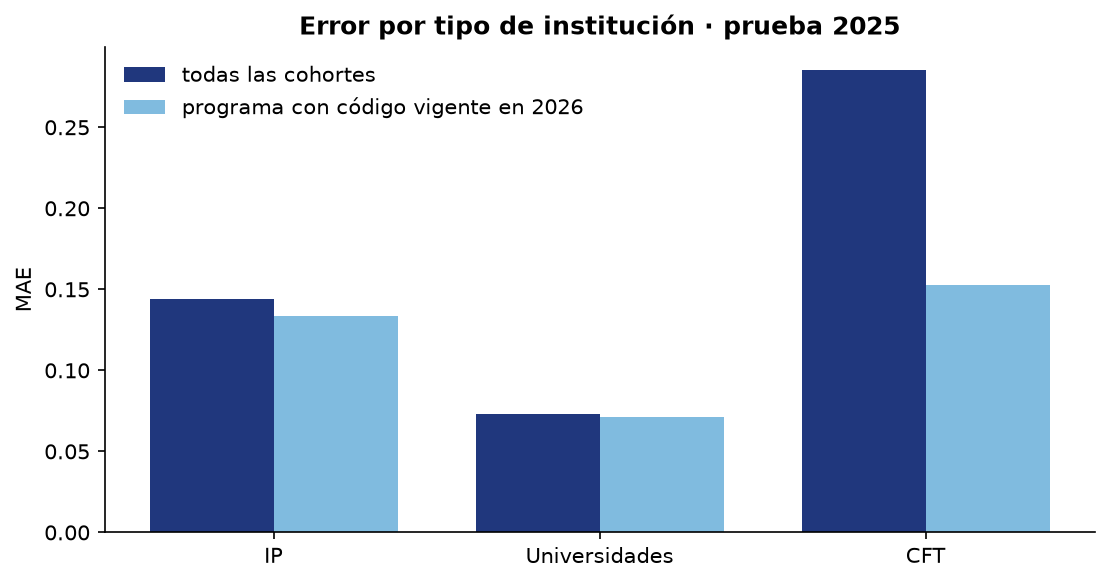

En 2025 hay 35 cohortes (2583 estudiantes) de 33 programas cuyo código no existe en 2026: su continuidad observada es 0.


In [12]:
print('Error por tipo de institución'); display(pd.read_csv('evidencia/error_por_tipo_institucion.csv', index_col=0))
print('Solo programas cuyo código sigue existiendo en 2026'); display(pd.read_csv('evidencia/error_por_tipo_codigo_vigente.csv', index_col=0))
print('Error por tamaño de cohorte'); display(pd.read_csv('evidencia/error_por_tamano_cohorte.csv', index_col=0))
print('Cupos, solo programas con código vigente'); display(pd.read_csv('evidencia/cupos_backtest_codigo_vigente.csv', index_col=0))
d2(Image('evidencia/fig_error_tipo.png'))
c = R['cupos']; print(f"En 2025 hay {c['cohortes_codigo_desaparece']} cohortes ({c['estudiantes_en_programas_que_desaparecen']} estudiantes) de {c['programas_codigo_desaparece']} programas cuyo código no existe en 2026: su continuidad observada es 0.")

## 7. Lectura de resultados, límites y riesgos
- **El modelo mejora a las líneas base** en continuidad (MAE 0,133 contra 0,154 de repetir la retención del año previo y 0,168 de la media) y en cupos por cohorte. Aun así el R² es modesto (0,23): sirve para anticipar, no para fijar cupos exactos.
- **Mayor error en CFT** (MAE 0,285, sesgo +0,154). Una parte importante viene de programas cuyo código desaparece en 2026; la base no permite distinguir un cierre de un cambio de código. El prototipo avisa cuando la cohorte es de CFT. Con los programas de código vigente el error en CFT baja a 0,152.
- **Cohortes pequeñas** (5–9 estudiantes) tienen el mayor error (MAE 0,208): una persona mueve varios puntos.
- **No predice el ingreso nuevo** (año 1): es un supuesto explícito o un dato del usuario.
- **Datos:** muestra del 4% de los programas; datos públicos y anonimizados, agregados por cohorte en memoria; no se exportan registros individuales. Ver `DATOS.md`.
- **Uso responsable:** la estimación apoya la planificación, no decide sobre personas. Usa proporción de mujeres y edad media como predictores de cohorte; no se evaluó equidad.

In [13]:
print('Reproducir la validación completa (requiere T04_muestra_SIES_2017_2026.zip):  python ejecutar_validacion.py T04_muestra_SIES_2017_2026.zip')
print('Regenerar el modelo si el .joblib no carga por versiones:                      python construir_modelo.py T04_muestra_SIES_2017_2026.zip .')

Reproducir la validación completa (requiere T04_muestra_SIES_2017_2026.zip):  python ejecutar_validacion.py T04_muestra_SIES_2017_2026.zip
Regenerar el modelo si el .joblib no carga por versiones:                      python construir_modelo.py T04_muestra_SIES_2017_2026.zip .
